# Fake News Detection: A Comparative Study of Logistic Regression, LSTM, and BERT

This notebook accompanies the experimental chapter of the dissertation and implements the full
pipeline used to compare three text classification approaches of increasing complexity — a
TF-IDF-based linear classifier, a recurrent neural network (LSTM), and a fine-tuned transformer
(BERT) — on the task of distinguishing fake from real news articles.

All three models are trained and evaluated on an identical dataset, split, and preprocessing
pipeline, which is the only way a comparison across such different model families is meaningful.
The notebook is organised as follows:

1. **Introduction** — environment configuration and reproducibility settings
2. **Data Loading** — acquisition and ingestion of the two source datasets
3. **Data Cleaning** — deduplication and text normalisation
4. **Exploratory Data Analysis** — class balance and article-length characteristics
5. **Data Splitting** — the stratified train/validation/test partition shared by all models
6. **Logistic Regression** — the classical baseline
7. **LSTM** — the recurrent deep learning baseline
8. **BERT** — the transformer model
9. **Model Comparison** — consolidated metrics and visualisations
10. **Conclusion** — summary of findings

## 1.1 Dataset

Two sources are combined to build a single corpus large enough, and varied enough in provenance, to
support a robust train/validation/test split:

- **ISOT Fake and Real News Dataset** — the primary corpus, comprising `Fake.csv` and `True.csv`.
- **WELFake (deduplicated)** — a second, independently compiled corpus. Because WELFake was found to
  overlap substantially with ISOT, every article shared between the two was removed in advance (see
  the accompanying data-preparation notes); the version loaded here, `dataset2_welfake_clean.csv`,
  contains only the non-overlapping remainder.

Both are reduced to a common two-column schema — `text` and `label`, with `label = 0` for fake and
`label = 1` for real articles — before being merged, deduplicated, and split. Validation and test
performance therefore reflect in-distribution generalisation across a combined, heterogeneous
corpus, rather than generalisation to a wholly unseen source.

Kaggle Project link: https://www.kaggle.com/code/khalidahamedshaik/fake-news-dissertation/edit/run/337204104

## 1.2 Imports

In [1]:
import os
import re
import string
import random
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.optim import AdamW           # torch.optim.AdamW rather than the now-removed transformers.AdamW
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, ConfusionMatrixDisplay
)

import joblib
from tqdm.auto import tqdm
from transformers import BertTokenizer, BertForSequenceClassification, get_linear_schedule_with_warmup

print(f'PyTorch {torch.__version__}  |  TensorFlow {tf.__version__}')

PyTorch 2.10.0+cu128  |  TensorFlow 2.20.0


## 1.3 Reproducibility and Device Configuration

A fixed seed is applied to every source of randomness used across the three modelling frameworks
(Python's own `random`, NumPy, PyTorch, and TensorFlow), and compute is detected automatically:
CUDA is preferred where available, falling back to Apple Silicon (MPS) and finally CPU. This lets
the notebook run unmodified on a Kaggle GPU session, a local Apple Silicon machine, or a CPU-only
environment.

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
tf.random.set_seed(SEED)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print('Random seed :', SEED)
print('PyTorch device :', device)
if device.type == 'cuda':
    print('  GPU:', torch.cuda.get_device_name(0))
tf_gpus = tf.config.list_physical_devices('GPU')
print('TensorFlow GPUs:', tf_gpus if tf_gpus else 'none (CPU)')

Random seed : 42
PyTorch device : cuda
  GPU: Tesla T4
TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1.4 Output Directories and Plot Styling

Every figure produced in this notebook is written to disk under `results/`, organised by figure
type, at publication quality (300 dpi, tight bounding box) — configured once here via
`rcParams` so no individual plotting cell needs to repeat it. A small, fixed colour is assigned to
each model and reused in every figure so that, for instance, BERT is always green and Logistic
Regression is always blue, regardless of which section of the notebook produced the plot.

In [3]:
RESULTS_DIR = 'results'
for sub in ['confusion_matrices', 'roc_curves', 'training_curves', 'classification_reports', 'comparison']:
    os.makedirs(os.path.join(RESULTS_DIR, sub), exist_ok=True)
os.makedirs('models', exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 100,          # on-screen rendering
    'savefig.dpi': 300,         # exported figure resolution
    'savefig.bbox': 'tight',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'legend.fontsize': 10,
    'axes.grid': True,
    'grid.alpha': 0.3,
})
sns.set_style('whitegrid')

MODEL_COLORS = {
    'Logistic Regression': 'royalblue',
    'LSTM': 'mediumpurple',
    'BERT': 'seagreen',
}

print('Output directories ready under results/ and models/.')

Output directories ready under results/ and models/.


# 2. Data Loading

## 2.1 File Paths

Both datasets are read directly from the local filesystem. Update the two paths below if your
copy of the data lives somewhere else.

In [ ]:
ISOT_DIR = './data/isot'                                   # expects Fake.csv and True.csv here
WELFAKE_CLEAN_PATH = './data/welfake/dataset2_welfake_clean.csv'

print('ISOT_DIR            :', ISOT_DIR)
print('WELFAKE_CLEAN_PATH  :', WELFAKE_CLEAN_PATH)

## 2.2 File Verification

In [ ]:
def verify_required_files(required):
    """Raise a single, informative error naming every missing file, rather than failing on the first."""
    missing = [f'{desc} (expected at {path})' for desc, path in required.items() if not os.path.exists(path)]
    if missing:
        raise FileNotFoundError('Missing required file(s):\n' + '\n'.join(f'  - {m}' for m in missing))
    for desc, path in required.items():
        print(f'{desc}: {path}  ({os.path.getsize(path) / 1e6:.1f} MB)')

verify_required_files({
    'ISOT Fake.csv': os.path.join(ISOT_DIR, 'Fake.csv'),
    'ISOT True.csv': os.path.join(ISOT_DIR, 'True.csv'),
    'Cleaned WELFake dataset': WELFAKE_CLEAN_PATH,
})

## 2.3 Loading and Schema Normalisation

In [7]:
df_fake = pd.read_csv(os.path.join(ISOT_DIR, 'Fake.csv'))
df_true = pd.read_csv(os.path.join(ISOT_DIR, 'True.csv'))
df_fake['label'] = 0
df_true['label'] = 1
print('ISOT — Fake:', df_fake.shape, '| Real:', df_true.shape)

df_welfake = pd.read_csv(WELFAKE_CLEAN_PATH)
if 'label' not in df_welfake.columns and 'class' in df_welfake.columns:
    df_welfake = df_welfake.rename(columns={'class': 'label'})
df_welfake = df_welfake[['text', 'label']]
print('WELFake (deduplicated against ISOT):', df_welfake.shape)

ISOT — Fake: (23481, 5) | Real: (21417, 5)
WELFake (deduplicated against ISOT): (26592, 2)


# 3. Data Cleaning

The two sources are merged into a single dataframe, exact duplicate articles are removed, the
corpus is shuffled, and every remaining article is passed through a single text-normalisation
function applied uniformly across the whole dataset — the same cleaning is therefore seen by all
three models downstream, which matters for a fair comparison.

In [8]:
df_all = pd.concat([
    df_fake[['text', 'label']], df_true[['text', 'label']], df_welfake
], axis=0).reset_index(drop=True)
print('Rows before deduplication:', len(df_all))

df_all = df_all.drop_duplicates(subset='text').reset_index(drop=True)
print('Rows after deduplication :', len(df_all))

df_all = df_all.sample(frac=1, random_state=SEED).reset_index(drop=True)
print()
print('Combined class balance:')
print(df_all['label'].value_counts().rename({0: 'Fake', 1: 'Real'}))

Rows before deduplication: 71490
Rows after deduplication : 62163

Combined class balance:
label
Real    34617
Fake    27546
Name: count, dtype: int64


## 3.1 Text Normalisation

`clean_article_text` lower-cases the text and strips bracketed references, URLs, HTML fragments,
punctuation, digits, and redundant whitespace — a standard normalisation pass for this kind of news
corpus, prior to any model-specific tokenisation.

In [9]:
def clean_article_text(text):
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'\W', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>+', '', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub(r'\w*\d\w*', '', text)
    return re.sub(r'\s+', ' ', text).strip()

df_all.dropna(subset=['text'], inplace=True)
df_all['text'] = df_all['text'].apply(clean_article_text)
df_all = df_all[df_all['text'].str.len() > 0].reset_index(drop=True)

print('Rows after cleaning:', len(df_all))

Rows after cleaning: 62158


# 4. Exploratory Data Analysis

Before splitting and modelling, it is worth briefly characterising the cleaned corpus: how balanced
the two classes are, and how article length is distributed, since both properties inform how the
results in later sections should be read.

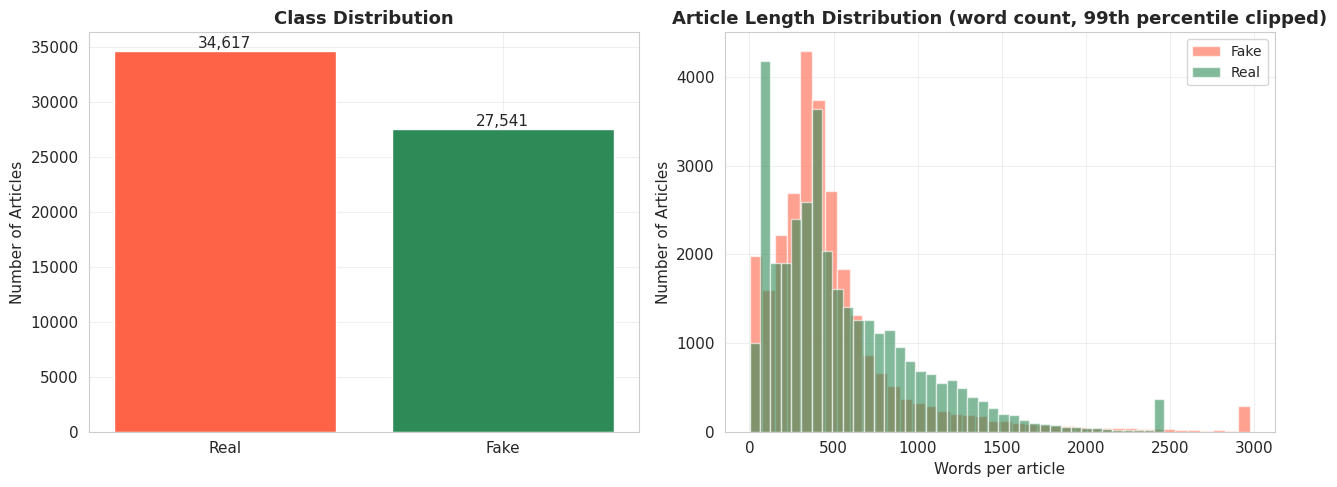

         count   mean    std  min    25%    50%    75%      max
label                                                          
Fake   27541.0  522.7  666.9  1.0  256.0  390.0  576.0  24387.0
Real   34617.0  576.2  560.3  1.0  237.0  426.0  785.0  14569.0


In [10]:
df_all['word_count'] = df_all['text'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

class_counts = df_all['label'].value_counts().rename({0: 'Fake', 1: 'Real'})
axes[0].bar(class_counts.index, class_counts.values, color=['tomato', 'seagreen'])
axes[0].set_title('Class Distribution')
axes[0].set_ylabel('Number of Articles')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 300, f'{v:,}', ha='center')

for label, name, color in [(0, 'Fake', 'tomato'), (1, 'Real', 'seagreen')]:
    subset = df_all.loc[df_all['label'] == label, 'word_count']
    axes[1].hist(subset.clip(upper=subset.quantile(0.99)), bins=40, alpha=0.6, label=name, color=color)
axes[1].set_title('Article Length Distribution (word count, 99th percentile clipped)')
axes[1].set_xlabel('Words per article'); axes[1].set_ylabel('Number of Articles')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison/eda_overview.png')
plt.show()

print(df_all.groupby('label')['word_count'].describe().rename(index={0: 'Fake', 1: 'Real'}).round(1))

The two classes are moderately imbalanced (roughly 56% real, 44% fake after merging and
deduplication) but not severely enough to require resampling — stratified splitting, used
throughout, is sufficient to preserve this ratio in every partition. Article length is broadly
comparable between classes, without an obvious length-based shortcut a classifier could exploit.

# 5. Data Splitting

A single stratified split is computed once and reused, unchanged, by all three models: 80% for
training, and the remaining 20% divided evenly into validation and test sets (10% each). Splitting
in two steps — first carving off the training set, then dividing what remains — combined with
`stratify` at each step keeps the Fake/Real ratio consistent across all three partitions.

In [11]:
X = df_all['text'].tolist()
y = df_all['label'].tolist()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print(f'Train      : {len(X_train):>6} ({len(X_train)/len(X):.1%})')
print(f'Validation : {len(X_val):>6} ({len(X_val)/len(X):.1%})')
print(f'Test       : {len(X_test):>6} ({len(X_test)/len(X):.1%})')

Train      :  49726 (80.0%)
Validation :   6216 (10.0%)
Test       :   6216 (10.0%)


# 6. Logistic Regression (Baseline Model)

## 6.0 Shared Evaluation Utilities

The same four helper functions are used for every model in this notebook, so that metrics,
classification reports, confusion matrices, and ROC curves are computed and presented identically
regardless of which model produced them. `results` is keyed by `(model, set)` rather than a plain
list, so re-running an evaluation cell — routine while iterating on a dissertation notebook —
overwrites the corresponding entry instead of silently duplicating it in the final comparison table.

In [12]:
results = {}          # {(model_name, set_name): metrics_dict} -- keyed to make re-running cells safe
training_times = {}  # model_name -> wall-clock training time in seconds

def report_metrics(model_name, set_name, y_true, y_pred, y_score, save_report=True):
    """Print and record Accuracy / Precision / Recall / F1 / ROC-AUC and the full classification
    report for one (model, set) pair, and persist the classification report to disk."""
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_score),
    }

    print(f'{model_name} — {set_name}')
    for name, value in metrics.items():
        print(f'  {name:<10}: {value:.4f}')

    report_df = pd.DataFrame(classification_report(y_true, y_pred, target_names=['Fake', 'Real'], output_dict=True)).T
    print()
    print(report_df.round(4))

    if save_report:
        fname = f"{RESULTS_DIR}/classification_reports/{model_name.lower().replace(' ', '_')}_{set_name.lower()}.csv"
        report_df.to_csv(fname)

    results[(model_name, set_name)] = {'Model': model_name, 'Set': set_name, **metrics}
    return metrics

def plot_confusion_pair(y_val_true, y_val_pred, y_test_true, y_test_pred, model_name, cmap='Blues'):
    """Validation and Test confusion matrices side by side in one figure."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, (y_t, y_p, title) in zip(axes, [(y_val_true, y_val_pred, 'Validation'), (y_test_true, y_test_pred, 'Test')]):
        cm = confusion_matrix(y_t, y_p)
        ConfusionMatrixDisplay(cm, display_labels=['Fake', 'Real']).plot(ax=ax, cmap=cmap, colorbar=False)
        ax.set_title(title)
    fig.suptitle(f'{model_name} — Confusion Matrices', fontweight='bold')
    plt.tight_layout()
    fname = f"{RESULTS_DIR}/confusion_matrices/{model_name.lower().replace(' ', '_')}_confusion_matrices.png"
    plt.savefig(fname)
    plt.show()

def plot_roc_pair(y_val_true, y_val_score, y_test_true, y_test_score, model_name, color=None):
    """Validation and Test ROC curves side by side in one figure."""
    color = color or MODEL_COLORS.get(model_name, 'royalblue')
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, (y_t, y_s, title) in zip(axes, [(y_val_true, y_val_score, 'Validation'), (y_test_true, y_test_score, 'Test')]):
        fpr, tpr, _ = roc_curve(y_t, y_s)
        auc = roc_auc_score(y_t, y_s)
        ax.plot(fpr, tpr, color=color, lw=2, label=f'AUC = {auc:.4f}')
        ax.plot([0, 1], [0, 1], 'k--', lw=1)
        ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
        ax.set_title(title); ax.legend(loc='lower right')
    fig.suptitle(f'{model_name} — ROC Curves', fontweight='bold')
    plt.tight_layout()
    fname = f"{RESULTS_DIR}/roc_curves/{model_name.lower().replace(' ', '_')}_roc_curves.png"
    plt.savefig(fname)
    plt.show()

def plot_training_curves(history, model_name, loss_key='loss', val_loss_key='val_loss',
                          acc_key='accuracy', val_acc_key='val_accuracy'):
    """Loss and accuracy curves side by side in one figure -- used by both LSTM and BERT."""
    epochs_ran = range(1, len(history[loss_key]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].plot(epochs_ran, history[loss_key],     'o-', color='royalblue', label='Train')
    axes[0].plot(epochs_ran, history[val_loss_key], 's-', color='tomato',    label='Validation')
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()

    axes[1].plot(epochs_ran, history[acc_key],     'o-', color='royalblue', label='Train')
    axes[1].plot(epochs_ran, history[val_acc_key], 's-', color='tomato',    label='Validation')
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()

    fig.suptitle(f'{model_name} — Training Curves', fontweight='bold')
    plt.tight_layout()
    fname = f"{RESULTS_DIR}/training_curves/{model_name.lower().replace(' ', '_')}_training_curves.png"
    plt.savefig(fname)
    plt.show()

print('Evaluation utilities defined.')

Evaluation utilities defined.


## 6.1 Feature Extraction

TF-IDF is fit **exclusively on the training partition**; validation and test text is transformed
using that fitted vectoriser only, so no vocabulary or document-frequency information from held-out
data leaks into the features.

In [13]:
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf   = tfidf.transform(X_val)
X_test_tfidf  = tfidf.transform(X_test)

print('Vocabulary size:', len(tfidf.vocabulary_))
print('Train / Val / Test shapes:', X_train_tfidf.shape, X_val_tfidf.shape, X_test_tfidf.shape)

Vocabulary size: 50000
Train / Val / Test shapes: (49726, 50000) (6216, 50000) (6216, 50000)


## 6.2 Training

In [14]:
t0 = time.time()
log_reg = LogisticRegression(max_iter=1000, random_state=SEED)
log_reg.fit(X_train_tfidf, y_train)
training_times['Logistic Regression'] = time.time() - t0
print(f'Trained in {training_times["Logistic Regression"]:.1f}s')

Trained in 3.4s


## 6.3 Evaluation

In [15]:
lr_val_preds = log_reg.predict(X_val_tfidf)
lr_val_probs = log_reg.predict_proba(X_val_tfidf)[:, 1]
report_metrics('Logistic Regression', 'Validation', y_val, lr_val_preds, lr_val_probs)

lr_test_preds = log_reg.predict(X_test_tfidf)
lr_test_probs = log_reg.predict_proba(
    X_test_tfidf)[:, 1]
report_metrics('Logistic Regression', 'Test', y_test, lr_test_preds, lr_test_probs)

Logistic Regression — Validation
  Accuracy  : 0.9476
  Precision : 0.9521
  Recall    : 0.9538
  F1-Score  : 0.9530
  ROC-AUC   : 0.9882

              precision  recall  f1-score    support
Fake             0.9418  0.9397    0.9407  2754.0000
Real             0.9521  0.9538    0.9530  3462.0000
accuracy         0.9476  0.9476    0.9476     0.9476
macro avg        0.9470  0.9468    0.9469  6216.0000
weighted avg     0.9475  0.9476    0.9475  6216.0000
Logistic Regression — Test
  Accuracy  : 0.9482
  Precision : 0.9538
  Recall    : 0.9532
  F1-Score  : 0.9535
  ROC-AUC   : 0.9887

              precision  recall  f1-score    support
Fake             0.9412  0.9419    0.9416  2754.0000
Real             0.9538  0.9532    0.9535  3462.0000
accuracy         0.9482  0.9482    0.9482     0.9482
macro avg        0.9475  0.9476    0.9475  6216.0000
weighted avg     0.9482  0.9482    0.9482  6216.0000


{'Accuracy': 0.9481981981981982,
 'Precision': 0.953757225433526,
 'Recall': 0.9532062391681109,
 'F1-Score': 0.9534816527015314,
 'ROC-AUC': np.float64(0.9887210955589203)}

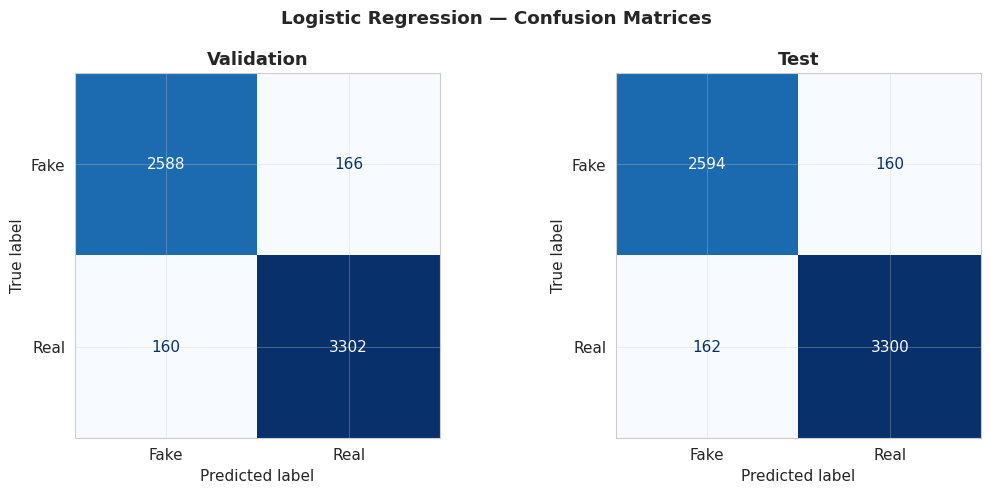

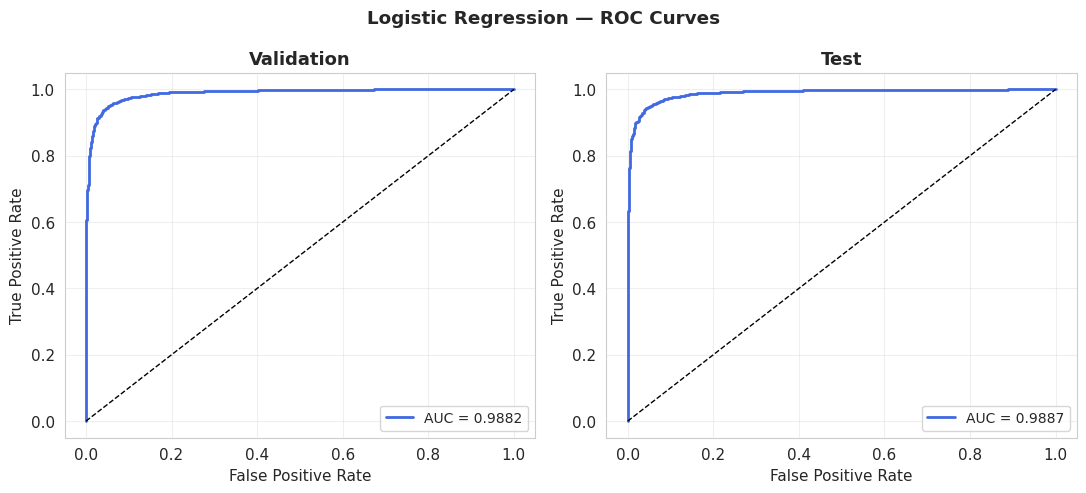

In [16]:
plot_confusion_pair(y_val, lr_val_preds, y_test, lr_test_preds, 'Logistic Regression', cmap='Blues')
plot_roc_pair(y_val, lr_val_probs, y_test, lr_test_probs, 'Logistic Regression')

## 6.4 Persisting the Model

In [17]:
joblib.dump(tfidf,   'models/tfidf_vectorizer.pkl')
joblib.dump(log_reg, 'models/logistic_regression.pkl')
print('Saved: models/tfidf_vectorizer.pkl, models/logistic_regression.pkl')

Saved: models/tfidf_vectorizer.pkl, models/logistic_regression.pkl


# 7. LSTM (Deep Learning Baseline)

## 7.1 Sequence Preparation

A Keras `Tokenizer` is fit **exclusively on the training partition** (mirroring the train-only-fit
rule applied to TF-IDF above), then used to convert all three splits to fixed-length integer
sequences via padding/truncation.

In [18]:
VOCAB_SIZE    = 20000
LSTM_MAX_LEN  = 128     # matches BERT's MAX_LEN below, for a comparable input window across models
EMBEDDING_DIM = 128

keras_tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
keras_tokenizer.fit_on_texts(X_train)

def to_padded_sequences(texts):
    return pad_sequences(keras_tokenizer.texts_to_sequences(texts), maxlen=LSTM_MAX_LEN, padding='post', truncating='post')

X_train_seq = to_padded_sequences(X_train)
X_val_seq   = to_padded_sequences(X_val)
X_test_seq  = to_padded_sequences(X_test)
y_train_arr, y_val_arr, y_test_arr = np.array(y_train), np.array(y_val), np.array(y_test)

print('Sequence shapes — Train:', X_train_seq.shape, '| Val:', X_val_seq.shape, '| Test:', X_test_seq.shape)

Sequence shapes — Train: (49726, 128) | Val: (6216, 128) | Test: (6216, 128)


## 7.2 Model Architecture

`Embedding → LSTM(128) → Dropout(0.5) → Dense(64, ReLU) → Dense(1, Sigmoid)`, compiled with binary
cross-entropy and Adam. The input shape is declared through an explicit `Input` layer rather than
the older `Embedding(input_length=...)` argument, which recent Keras releases deprecate in favour of
this form — a purely syntactic change that leaves the architecture itself identical.

In [37]:
lstm_model = Sequential([
    Input(shape=(LSTM_MAX_LEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    LSTM(64),
    Dropout(0.6),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid'),
])
lstm_model.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=1e-3), metrics=['accuracy'])
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 128, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,613,633 (9.97 MB)

 Trainable params: 2,613,633 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

## 7.3 Training

Three callbacks manage training automatically: `EarlyStopping` halts once validation loss stops
improving and restores the best-performing weights; `ModelCheckpoint` saves that best epoch to disk
as training proceeds; `ReduceLROnPlateau` halves the learning rate if validation loss plateaus
before early stopping triggers.

In [38]:
LSTM_EPOCHS     = 15
LSTM_BATCH_SIZE = 64
lstm_checkpoint_path = 'models/lstm.keras'

callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    ModelCheckpoint(lstm_checkpoint_path, monitor='val_loss', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
]

t0 = time.time()
lstm_history = lstm_model.fit(
    X_train_seq, y_train_arr,
    validation_data=(X_val_seq, y_val_arr),
    epochs=LSTM_EPOCHS, batch_size=LSTM_BATCH_SIZE,
    callbacks=callbacks, verbose=1
)
training_times['LSTM'] = time.time() - t0
print(f'Trained in {training_times["LSTM"]:.1f}s')

lstm_model = load_model(lstm_checkpoint_path)  # ensure the best checkpoint, not necessarily the final epoch, is evaluated

Epoch 1/15
776/777 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7092 - loss: 0.5679
Epoch 1: val_loss improved from None to 0.45503, saving model to models/lstm.keras

Epoch 1: finished saving model to models/lstm.keras
777/777 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.7636 - loss: 0.5232 - val_accuracy: 0.8042 - val_loss: 0.4550 - learning_rate: 0.0010
Epoch 2/15
775/777 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8227 - loss: 0.4344
Epoch 2: val_loss improved from 0.45503 to 0.35914, saving model to models/lstm.keras

Epoch 2: finished saving model to models/lstm.keras
777/777 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8343 - loss: 0.4119 - val_accuracy: 0.8597 - val_loss: 0.3591 - learning_rate: 0.0010
Epoch 3/15
773/777 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8737 - loss: 0.3438
Epoch 3: val_loss improved from 0.35914 to 0.35517, saving model to models/lstm.keras

Epoch 3: finished saving model to models/lstm.keras
777/777 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step -

## 7.4 Training Curves

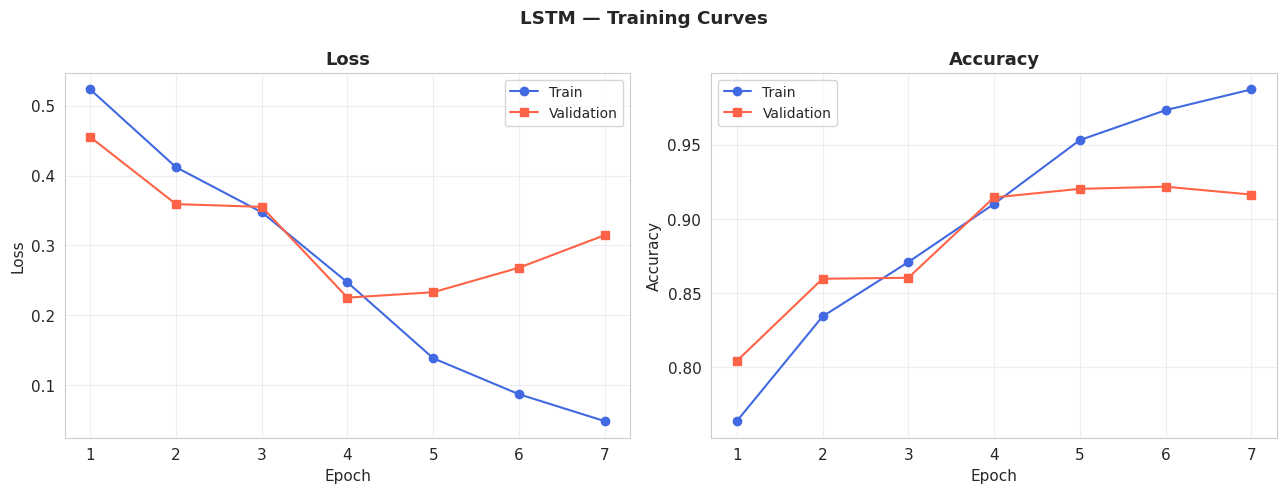

In [39]:
plot_training_curves(lstm_history.history, 'LSTM')

## 7.5 Evaluation

In [40]:
lstm_val_probs = lstm_model.predict(X_val_seq, verbose=0).ravel()
lstm_val_preds = (lstm_val_probs > 0.5).astype(int)
report_metrics('LSTM', 'Validation', y_val_arr, lstm_val_preds, lstm_val_probs)

lstm_test_probs = lstm_model.predict(X_test_seq, verbose=0).ravel()
lstm_test_preds = (lstm_test_probs > 0.5).astype(int)
report_metrics('LSTM', 'Test', y_test_arr, lstm_test_preds, lstm_test_probs)

LSTM — Validation
  Accuracy  : 0.9146
  Precision : 0.9340
  Recall    : 0.9110
  F1-Score  : 0.9224
  ROC-AUC   : 0.9693

              precision  recall  f1-score    support
Fake             0.8915  0.9190    0.9051  2754.0000
Real             0.9340  0.9110    0.9224  3462.0000
accuracy         0.9146  0.9146    0.9146     0.9146
macro avg        0.9127  0.9150    0.9137  6216.0000
weighted avg     0.9152  0.9146    0.9147  6216.0000
LSTM — Test
  Accuracy  : 0.9204
  Precision : 0.9380
  Recall    : 0.9177
  F1-Score  : 0.9277
  ROC-AUC   : 0.9729

              precision  recall  f1-score    support
Fake             0.8993  0.9237    0.9113  2754.0000
Real             0.9380  0.9177    0.9277  3462.0000
accuracy         0.9204  0.9204    0.9204     0.9204
macro avg        0.9186  0.9207    0.9195  6216.0000
weighted avg     0.9208  0.9204    0.9205  6216.0000


{'Accuracy': 0.9203667953667953,
 'Precision': 0.9379982285208148,
 'Recall': 0.9176776429809359,
 'F1-Score': 0.9277266754270697,
 'ROC-AUC': np.float64(0.972945082348578)}

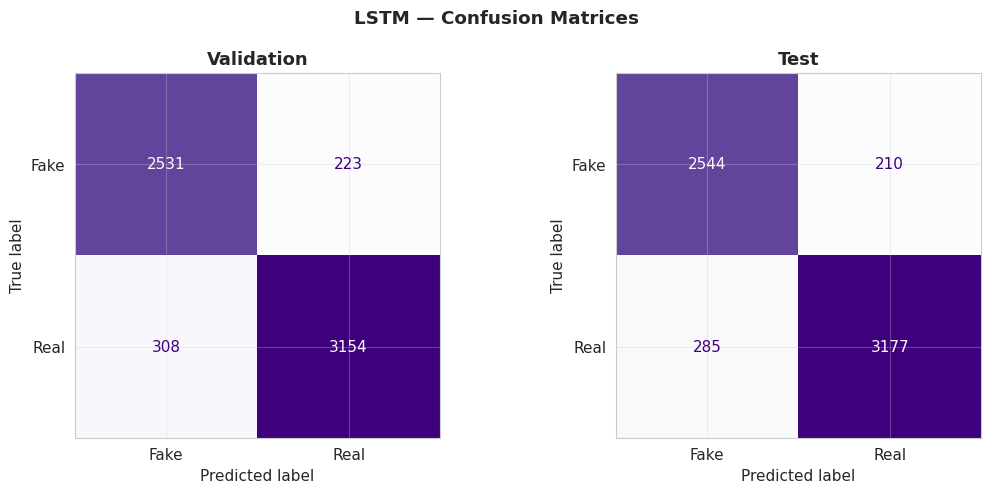

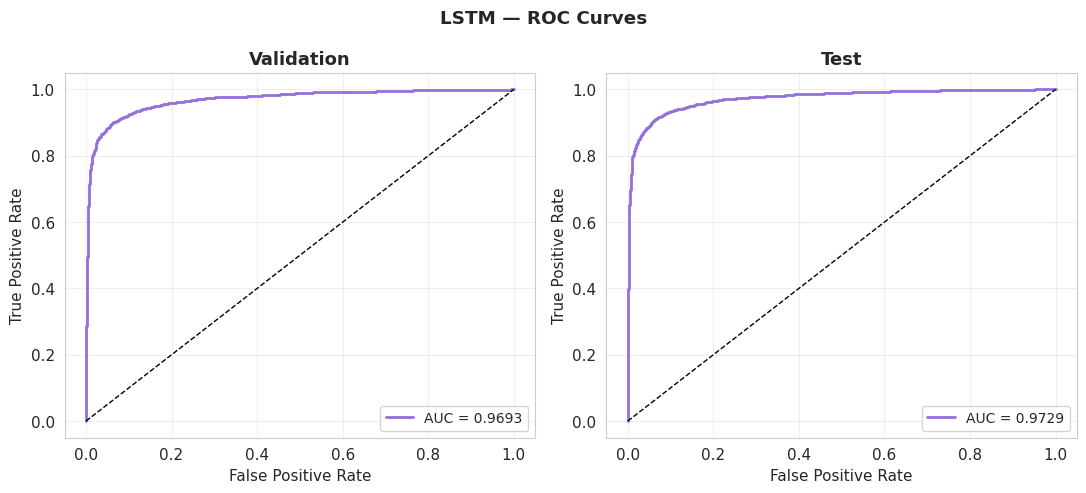

In [41]:
plot_confusion_pair(y_val_arr, lstm_val_preds, y_test_arr, lstm_test_preds, 'LSTM', cmap='Purples')
plot_roc_pair(y_val_arr, lstm_val_probs, y_test_arr, lstm_test_probs, 'LSTM')

## 7.6 Persisting the Model

(The model weights were already saved automatically by `ModelCheckpoint` during training.)

In [42]:
joblib.dump(keras_tokenizer, 'models/lstm_tokenizer.pkl')
print('Saved: models/lstm_tokenizer.pkl  (model already saved at models/lstm.keras)')

Saved: models/lstm_tokenizer.pkl  (model already saved at models/lstm.keras)


# 8. BERT (Transformer Model)

Architecture, tokenizer, sequence length, batch size, learning rate, scheduler, optimiser, number of
epochs, and the training loop itself are all unchanged from the earlier stages of this project —
only the data feeding into them differs (Sections 2–5 above). `torch.optim.AdamW` is used in place
of the now-removed `transformers.AdamW`.

## 8.1 Tokenization

In [25]:
MODEL_NAME = 'bert-base-uncased'
MAX_LEN    = 128
BATCH_SIZE = 32

bert_tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

def bert_tokenize(texts, labels):
    enc = bert_tokenizer(texts, padding='max_length', truncation=True, max_length=MAX_LEN, return_tensors='pt')
    return TensorDataset(enc['input_ids'], enc['attention_mask'], torch.tensor(labels, dtype=torch.long))

print('Tokenizing train / validation / test...')
train_ds = bert_tokenize(X_train, y_train)
val_ds   = bert_tokenize(X_val, y_val)
test_ds  = bert_tokenize(X_test, y_test)

# num_workers=0: multi-process DataLoader workers were triggering a harmless but noisy
# "can only test a child process" AssertionError during interpreter shutdown on Kaggle's
# environment. Single-process loading sidesteps it entirely with no effect on batching or results.
train_loader = DataLoader(train_ds, sampler=RandomSampler(train_ds),    batch_size=BATCH_SIZE, num_workers=0)
val_loader   = DataLoader(val_ds,   sampler=SequentialSampler(val_ds),  batch_size=BATCH_SIZE, num_workers=0)
test_loader  = DataLoader(test_ds,  sampler=SequentialSampler(test_ds), batch_size=BATCH_SIZE, num_workers=0)

print(f'Batches — Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}')

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizing train / validation / test...
Batches — Train: 1554 | Val: 195 | Test: 195


## 8.2 Model Configuration

In [26]:
EPOCHS = 3
LR     = 2e-5
WARMUP = 0.1

bert_model = BertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

n_gpus = torch.cuda.device_count() if torch.cuda.is_available() else 0
if n_gpus > 1:
    bert_model = torch.nn.DataParallel(bert_model)
bert_model = bert_model.to(device)

total_steps  = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP)

optimizer = AdamW(bert_model.parameters(), lr=LR, weight_decay=0.01)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

print(f'Total steps: {total_steps} | Warmup steps: {warmup_steps}')

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total steps: 4662 | Warmup steps: 466


## 8.3 Training

In [27]:
bert_history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}

def run_epoch(loader, train=True):
    bert_model.train() if train else bert_model.eval()
    total_loss, correct, total = 0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for batch in tqdm(loader, desc='Training' if train else 'Evaluating', leave=False):
            ids, mask, labels = [b.to(device) for b in batch]
            out = bert_model(input_ids=ids, attention_mask=mask, labels=labels)
            loss = out.loss.mean() if n_gpus > 1 else out.loss
            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
            total_loss += loss.item()
            correct += (out.logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / len(loader), correct / total

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    vl_loss, vl_acc = run_epoch(val_loader, train=False)
    bert_history['loss'].append(tr_loss)
    bert_history['val_loss'].append(vl_loss)
    bert_history['accuracy'].append(tr_acc)
    bert_history['val_accuracy'].append(vl_acc)
    print(f'Epoch {epoch}/{EPOCHS}  Train loss={tr_loss:.4f} acc={tr_acc:.4f}  Val loss={vl_loss:.4f} acc={vl_acc:.4f}')
training_times['BERT'] = time.time() - t0
print(f'Trained in {training_times["BERT"]:.1f}s')

Training:   0%|          | 0/1554 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/195 [00:00<?, ?it/s]

Epoch 1/3  Train loss=0.2303 acc=0.8964  Val loss=0.1412 acc=0.9459


Training:   0%|          | 0/1554 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/195 [00:00<?, ?it/s]

Epoch 2/3  Train loss=0.0945 acc=0.9663  Val loss=0.1130 acc=0.9604


Training:   0%|          | 0/1554 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/195 [00:00<?, ?it/s]

Epoch 3/3  Train loss=0.0431 acc=0.9877  Val loss=0.1651 acc=0.9630
Trained in 2284.2s


## 8.4 Training Curves

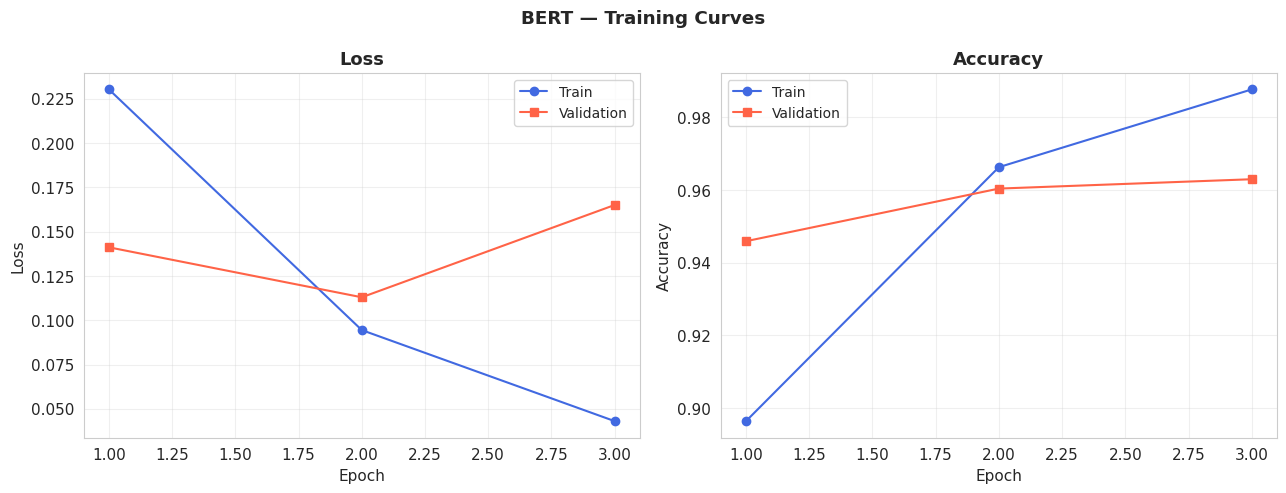

In [28]:
plot_training_curves(bert_history, 'BERT')

## 8.5 Evaluation

In [29]:
def get_predictions(loader):
    bert_model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for batch in tqdm(loader, desc='Predicting', leave=False):
            ids, mask, labels = [b.to(device) for b in batch]
            out = bert_model(input_ids=ids, attention_mask=mask)
            probs = torch.softmax(out.logits, dim=1)[:, 1]
            all_preds.extend(out.logits.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return np.array(all_preds), np.array(all_labels), np.array(all_probs)

bert_val_preds, bert_val_labels, bert_val_probs = get_predictions(val_loader)
report_metrics('BERT', 'Validation', bert_val_labels, bert_val_preds, bert_val_probs)

bert_test_preds, bert_test_labels, bert_test_probs = get_predictions(test_loader)
report_metrics('BERT', 'Test', bert_test_labels, bert_test_preds, bert_test_probs)

Predicting:   0%|          | 0/195 [00:00<?, ?it/s]

BERT — Validation
  Accuracy  : 0.9630
  Precision : 0.9728
  Recall    : 0.9604
  F1-Score  : 0.9666
  ROC-AUC   : 0.9932

              precision  recall  f1-score   support
Fake             0.9510  0.9662    0.9586  2754.000
Real             0.9728  0.9604    0.9666  3462.000
accuracy         0.9630  0.9630    0.9630     0.963
macro avg        0.9619  0.9633    0.9626  6216.000
weighted avg     0.9632  0.9630    0.9630  6216.000


Predicting:   0%|          | 0/195 [00:00<?, ?it/s]

BERT — Test
  Accuracy  : 0.9617
  Precision : 0.9697
  Recall    : 0.9613
  F1-Score  : 0.9655
  ROC-AUC   : 0.9933

              precision  recall  f1-score    support
Fake             0.9519  0.9622    0.9570  2754.0000
Real             0.9697  0.9613    0.9655  3462.0000
accuracy         0.9617  0.9617    0.9617     0.9617
macro avg        0.9608  0.9618    0.9613  6216.0000
weighted avg     0.9618  0.9617    0.9617  6216.0000


{'Accuracy': 0.9617117117117117,
 'Precision': 0.9696969696969697,
 'Recall': 0.9612940496822646,
 'F1-Score': 0.9654772265738323,
 'ROC-AUC': np.float64(0.993330954565535)}

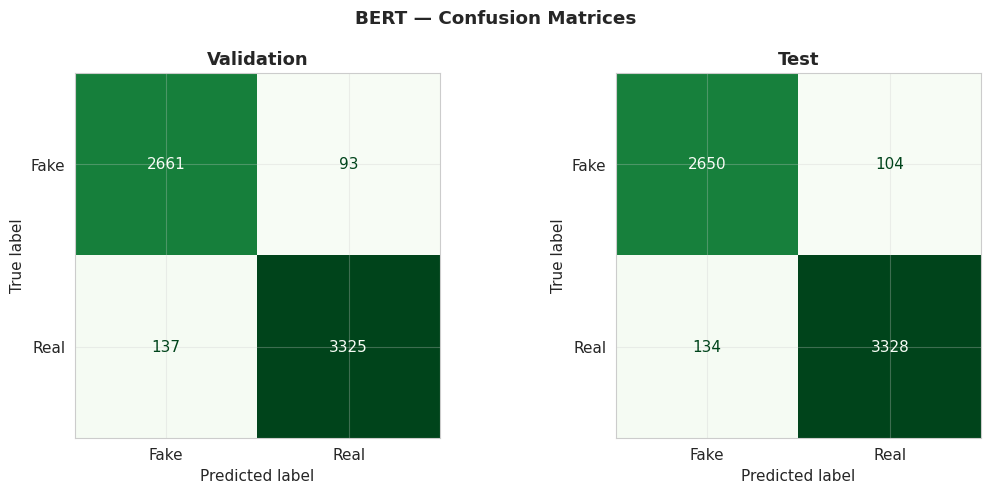

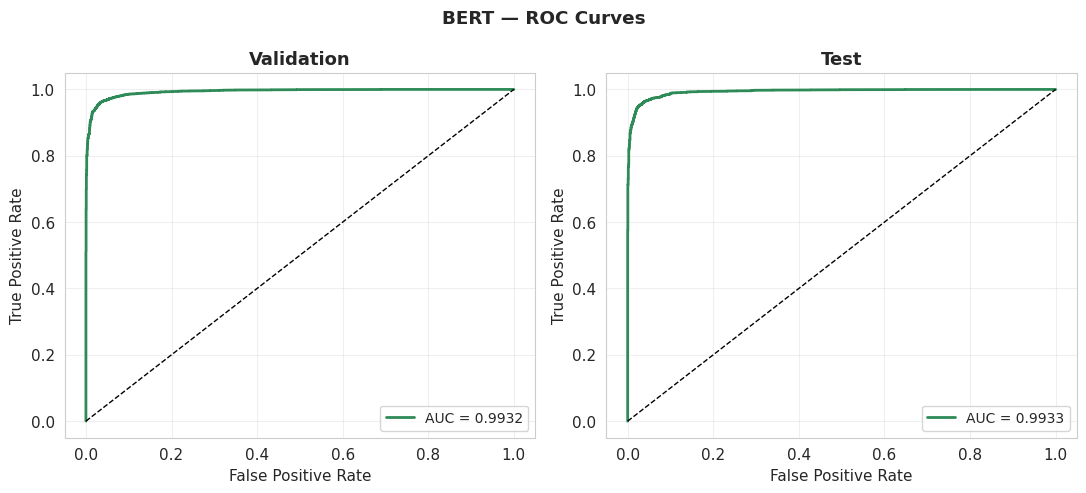

In [30]:
plot_confusion_pair(bert_val_labels, bert_val_preds, bert_test_labels, bert_test_preds, 'BERT', cmap='Greens')
plot_roc_pair(bert_val_labels, bert_val_probs, bert_test_labels, bert_test_probs, 'BERT')

## 8.6 Persisting the Model

In [31]:
bert_save_dir = 'models/bert'
os.makedirs(bert_save_dir, exist_ok=True)
model_to_save = bert_model.module if isinstance(bert_model, torch.nn.DataParallel) else bert_model
model_to_save.save_pretrained(bert_save_dir)
bert_tokenizer.save_pretrained(bert_save_dir)
print(f'Saved BERT model and tokenizer to {bert_save_dir}/')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved BERT model and tokenizer to models/bert/


# 9. Model Comparison

## 9.1 Consolidated Results

Every `(model, set)` pair evaluated above is collected into a single table. The headline comparison
uses Test-set performance, since that partition was touched by no model at any point during training
or hyperparameter/checkpoint selection; the full detail, including Validation-set figures, is written
to `results/classification_reports/` and `results/comparison/metrics_all.csv` for reference.

In [43]:
all_results = pd.DataFrame(results.values())
all_results.to_csv(f'{RESULTS_DIR}/comparison/metrics_all.csv', index=False)

comparison = all_results[all_results['Set'] == 'Test'].copy()
comparison['Training Time (s)'] = comparison['Model'].map(training_times).round(1)
comparison = comparison[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Training Time (s)']]
comparison = comparison.round(4).sort_values('F1-Score', ascending=False).reset_index(drop=True)
comparison.to_csv(f'{RESULTS_DIR}/comparison/comparison_test_set.csv', index=False)

best_model = comparison.iloc[0]['Model']
print(f'Best-performing model on the Test set (by F1-Score): {best_model}')

comparison.style.highlight_max(subset=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'], color='#c6f6d5')

Best-performing model on the Test set (by F1-Score): BERT


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s)
0,BERT,0.961700,0.969700,0.961300,0.965500,0.993300,2284.200000
1,Logistic Regression,0.948200,0.953800,0.953200,0.953500,0.988700,3.400000
2,LSTM,0.920400,0.938000,0.917700,0.927700,0.972900,55.700000


## 9.2 Metric Comparison

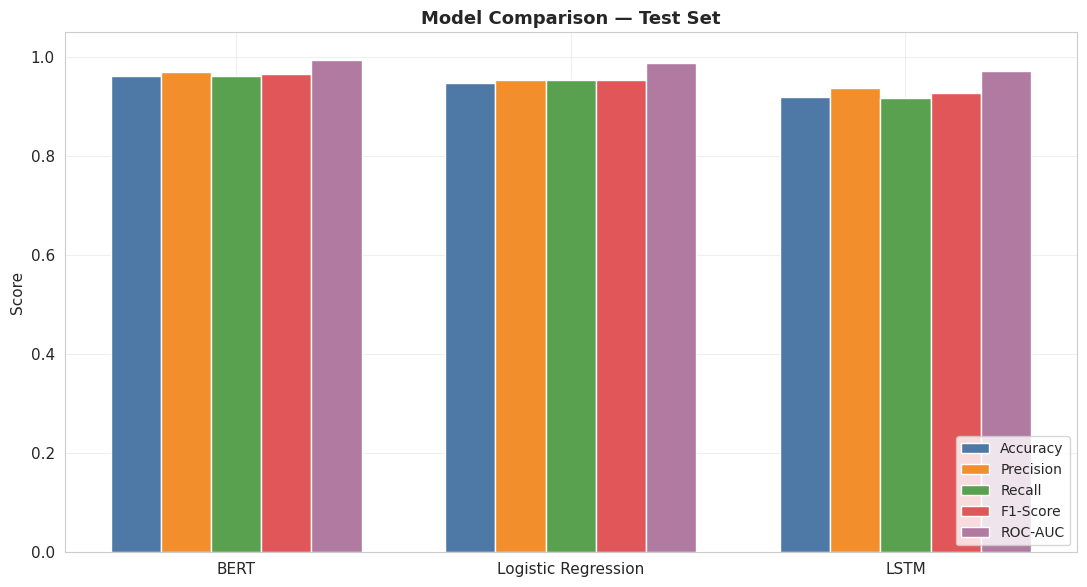

In [44]:
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
colors = ['#4E79A7', '#F28E2B', '#59A14F', '#E15759', '#B07AA1']

x = np.arange(len(comparison))
width = 0.15

fig, ax = plt.subplots(figsize=(11, 6))

for i, (metric, color) in enumerate(zip(metric_names, colors)):
    ax.bar(
        x + i * width,
        comparison[metric],
        width,
        label=metric,
        color=color
    )

ax.set_xticks(x + width * (len(metric_names) - 1) / 2)
ax.set_xticklabels(comparison['Model'])
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Model Comparison — Test Set')
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison/metric_comparison.png', dpi=300)
plt.show()

## 9.3 Combined ROC Curve

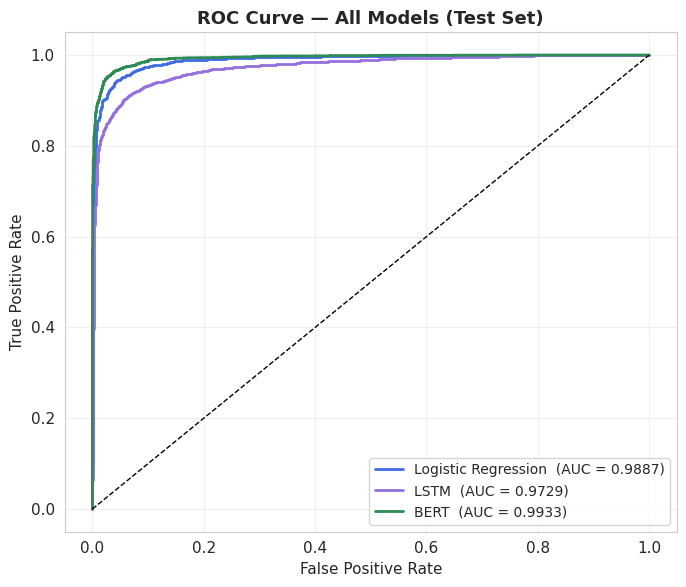

In [45]:
plt.figure(figsize=(7, 6))
for model_name, y_t, y_s in [
    ('Logistic Regression', y_test, lr_test_probs),
    ('LSTM', y_test_arr, lstm_test_probs),
    ('BERT', bert_test_labels, bert_test_probs),
]:
    fpr, tpr, _ = roc_curve(y_t, y_s)
    auc = roc_auc_score(y_t, y_s)
    plt.plot(fpr, tpr, lw=2, color=MODEL_COLORS[model_name], label=f'{model_name}  (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve — All Models (Test Set)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison/combined_roc_curve.png')
plt.show()

## Reproducibility Summary

| Artefact | Location |
|---|---|
| Trained models | `models/logistic_regression.pkl`, `models/lstm.keras`, `models/bert/` |
| TF-IDF vectoriser / LSTM tokenizer | `models/tfidf_vectorizer.pkl`, `models/lstm_tokenizer.pkl` |
| Per-model, per-split classification reports | `results/classification_reports/` |
| Confusion matrices (Validation + Test, per model) | `results/confusion_matrices/` |
| ROC curves (Validation + Test, per model) | `results/roc_curves/` |
| Training curves (LSTM, BERT) | `results/training_curves/` |
| Full metrics table and comparison figures | `results/comparison/` |

Random seed `42` is applied to Python, NumPy, PyTorch, and TensorFlow; the same fixed 80/10/10
stratified split is reused, unmodified, by all three models.